<a href="https://colab.research.google.com/github/ali-yyyy/Deep-Learning-Lab/blob/main/DL_LAB05_232411_Ali_Asghar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ali Asghar
# 232411
# Deep Learning Lab 5

# MNIST Practical


Task 1 — Import Libraries

In [1]:
# Import TensorFlow for deep learning.
import tensorflow as tf
# Import Keras for model building.
from tensorflow import keras
# Import CNN and other neural-network layers.
from tensorflow.keras import layers
# Import NumPy for numerical operations.
import numpy as np
# Import Matplotlib for images and graphs.
import matplotlib.pyplot as plt
# Import Seaborn for the confusion matrix.
import seaborn as sns
# Import evaluation metrics.
from sklearn.metrics import confusion_matrix, classification_report
# Display the TensorFlow version.
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


Task 2 — Load and Inspect MNIST

In [2]:
# Load 60,000 training and 10,000 testing MNIST images.
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
# Print image and label shapes.
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)
# Print the available classes.
print("Classes:", np.unique(y_train))
# Print original pixel range.
print("Pixel range:", x_train.min(), "to", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Classes: [0 1 2 3 4 5 6 7 8 9]
Pixel range: 0 to 255


Task 3 — Visualize MNIST

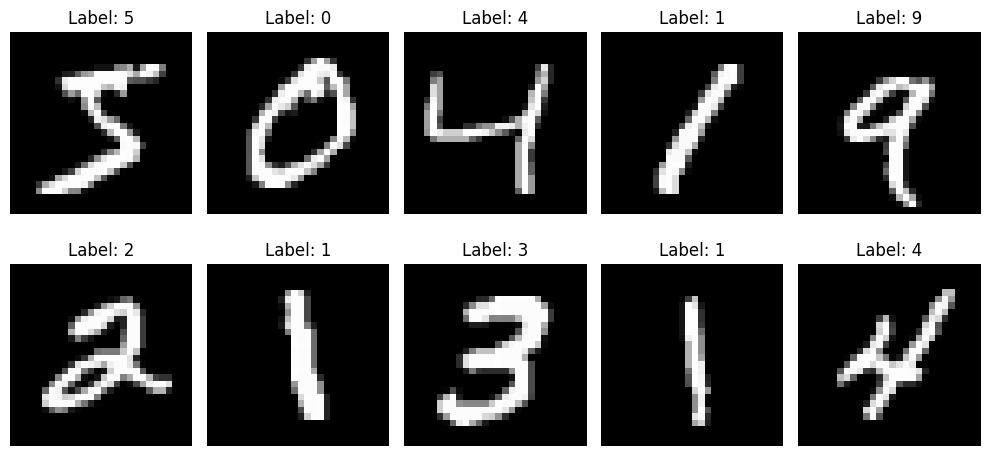

In [10]:
# Create space for ten images.
plt.figure(figsize=(10, 5))
# Display ten training examples.
for i in range(10):
# Select a subplot position.
    plt.subplot(2, 5, i + 1)
    # Display the grayscale image.
    plt.imshow(x_train[i], cmap="gray")
    # Show the correct label.
    plt.title("Label: " + str(y_train[i]))
    # Hide axes.
    plt.axis("off")
    # Improve spacing and show the figure.
plt.tight_layout()
plt.show()

Task 4 — Normalize and Reshape for CNN

In [5]:
# Convert training images to floating point and normalize 0-255 to 0-1.
x_train = x_train.astype("float32") / 255.0
# Apply the same preprocessing to test images.
x_test = x_test.astype("float32") / 255.0
# Add the grayscale channel dimension: 28x28 becomes 28x28x1.
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)
# Display CNN-ready shapes.
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


Task 5 — Build Baseline MNIST CNN

Architecture: Input 28×28×1 → Conv2D 32 (3×3) → ReLU → MaxPool 2×2 → Conv2D 64 (3×3) → ReLU →
MaxPool 2×2 → Flatten → Dense 128 → ReLU → Dense 10 → Softmax.

In [6]:
# Create a sequential CNN model.
model = keras.Sequential([
# Define the grayscale MNIST input shape.
layers.Input(shape=(28, 28, 1)),
# Learn 32 local features using 3x3 filters.
layers.Conv2D(32, (3, 3), activation="relu"),
# Reduce spatial dimensions by 2.
layers.MaxPooling2D((2, 2)),
# Learn 64 higher-level features.
layers.Conv2D(64, (3, 3), activation="relu"),
# Reduce spatial dimensions again.
layers.MaxPooling2D((2, 2)),
# Convert feature maps to one vector.
layers.Flatten(),
# Learn a compact classification representation.
layers.Dense(128, activation="relu"),
# Produce probabilities for digits 0-9.
layers.Dense(10, activation="softmax")
])
# Display the model structure.
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Task 6 — Compile and Train

In [8]:
# Configure the model before training.
model.compile(
    # Adam is an adaptive gradient optimizer.
    optimizer="adam",
    # Integer labels 0-9 use sparse categorical crossentropy.
    loss="sparse_categorical_crossentropy",
    # Track classification accuracy.
    metrics=["accuracy"]
)

# Train for ten epochs using mini-batches of 128 images.
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=1
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 44s 91ms/step - accuracy: 0.9629 - loss: 0.1230 - val_accuracy: 0.9852 - val_loss: 0.0499
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 92ms/step - accuracy: 0.9843 - loss: 0.0521 - val_accuracy: 0.9853 - val_loss: 0.0447
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 91ms/step - accuracy: 0.9890 - loss: 0.0362 - val_accuracy: 0.9897 - val_loss: 0.0320
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 89ms/step - accuracy: 0.9909 - loss: 0.0277 - val_accuracy: 0.9903 - val_loss: 0.0331
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 90ms/step - accuracy: 0.9936 - loss: 0.0214 - val_accuracy: 0.9905 - val_loss: 0.0286
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 85s 96ms/step - accuracy: 0.9948 - loss: 0.0166 - val_accuracy: 0.9908 - val_loss: 0.0282
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 44s 94ms/step - accuracy: 0.9953 - loss: 0.0144 - val_accuracy: 0.9907 - val_loss: 0.0293
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 80s 91ms/step - accuracy: 0.9966 - loss: 0.0099 - 

Task 7 — Plot Accuracy and Loss

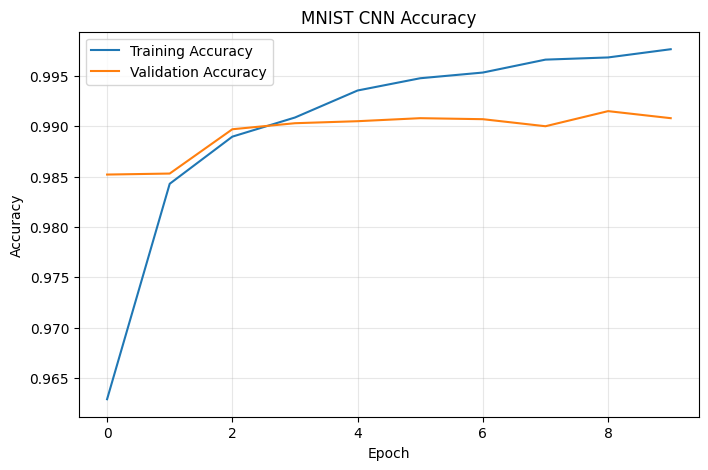

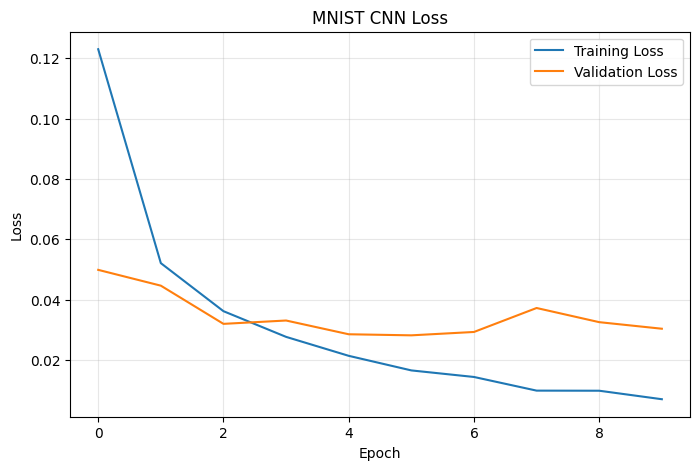

In [9]:
# Plot training and validation accuracy.
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MNIST CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
# Plot training and validation loss.
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("MNIST CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Task 8 — Evaluate, Predict and Analyze Errors

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9908 - loss: 0.0304
Test Loss: 0.030389461666345596
Test Accuracy: 0.9908000230789185
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Predicted: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 5 4]
Actual:  [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


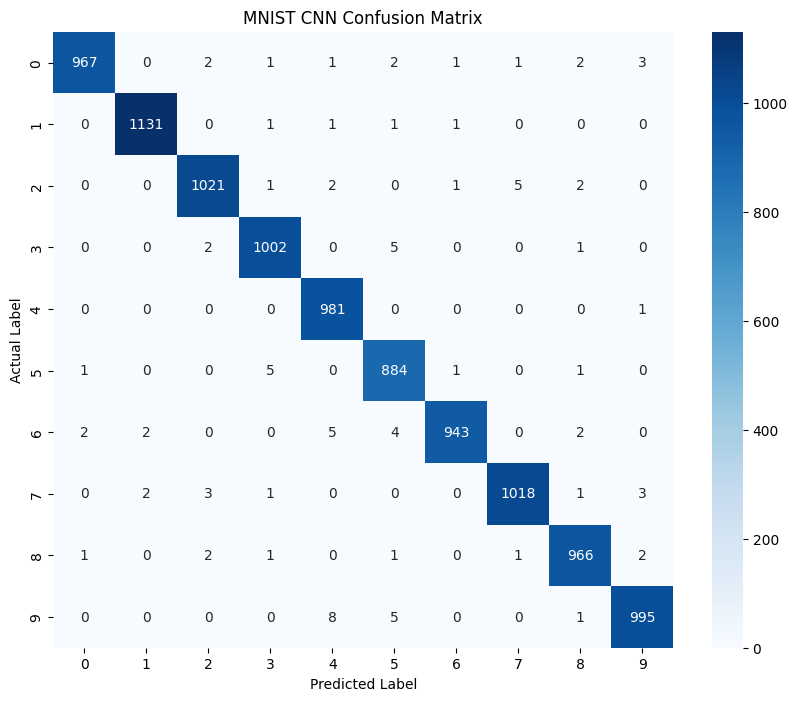

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       980
           1       1.00      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.98      1.00      0.99       982
           5       0.98      0.99      0.99       892
           6       1.00      0.98      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

Incorrect predictions: 92


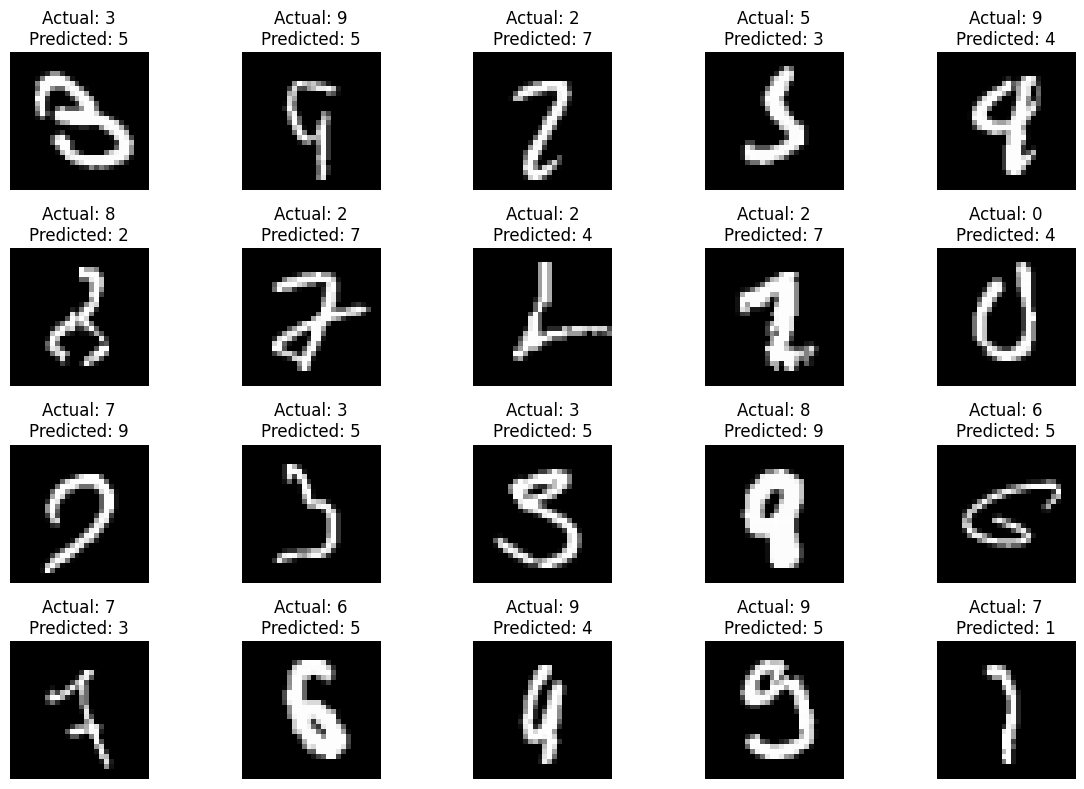

In [11]:
# Evaluate on the unseen test set.
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
# Generate class probabilities.
predictions = model.predict(x_test)
# Select the class with the highest probability.
predicted_labels = np.argmax(predictions, axis=1)
# Print the first twenty predictions and actual labels.
print("Predicted:", predicted_labels[:20])
print("Actual: ", y_test[:20])
# Build the confusion matrix.
cm = confusion_matrix(y_test, predicted_labels)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=range(10), yticklabels=range(10))
plt.title("MNIST CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()
# Print precision, recall and F1-score.
print(classification_report(y_test, predicted_labels))
# Find incorrect predictions.
incorrect = np.where(predicted_labels != y_test)[0]
print("Incorrect predictions:", len(incorrect))
# Display up to twenty errors.
plt.figure(figsize=(12, 8))
for i in range(min(20, len(incorrect))):
    idx = incorrect[i]
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title(f"Actual: {y_test[idx]}\nPredicted: {predicted_labels[idx]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

# CIFAR-10 Practical

Task 9 — Load, Inspect and Visualize CIFAR-10

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 846s 5us/step
Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


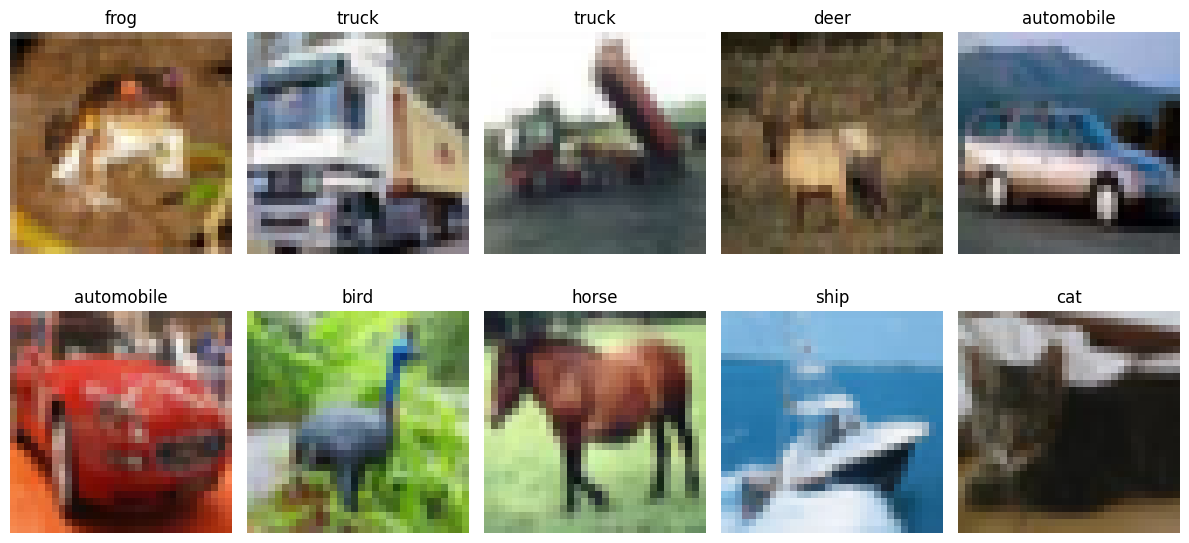

In [13]:
# Load CIFAR-10 from Keras.
(x_train_cifar, y_train_cifar), (x_test_cifar, y_test_cifar) = keras.datasets.cifar10.load_data()
# Define the ten class names.
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
# Print shapes.
print("Training images:", x_train_cifar.shape)
print("Testing images:", x_test_cifar.shape)
# Visualize ten examples.
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_cifar[i])
    plt.title(class_names[int(y_train_cifar[i][0])])
    plt.axis("off")
plt.tight_layout()
plt.show()

Task 10 — Normalize CIFAR-10

In [14]:
# Normalize RGB pixels from 0-255 to 0-1.
x_train_cifar = x_train_cifar.astype("float32") / 255.0
x_test_cifar = x_test_cifar.astype("float32") / 255.0
# Remove the extra label dimension.
y_train_cifar = y_train_cifar.squeeze()
y_test_cifar = y_test_cifar.squeeze()
# Confirm the final shapes.
print("Training shape:", x_train_cifar.shape)
print("Testing shape:", x_test_cifar.shape)

Training shape: (50000, 32, 32, 3)
Testing shape: (10000, 32, 32, 3)


Task 11 — Build and Train CIFAR-10 CNN

In [15]:
# Create a deeper baseline CNN for RGB object images.
cifar_model = keras.Sequential([
    # Define the 32x32 RGB input.
    layers.Input(shape=(32, 32, 3)),

    # First feature-extraction block.
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Second feature-extraction block.
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Convert feature maps to a vector.
    layers.Flatten(),

    # Fully connected classification layer.
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.50),

    # Ten CIFAR-10 class probabilities.
    layers.Dense(10, activation="softmax")
])

# Display the model summary.
cifar_model.summary()

# Compile the model.
cifar_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Train the model.
cifar_history = cifar_model.fit(
    x_train_cifar,
    y_train_cifar,
    epochs=10,
    batch_size=128,
    validation_data=(x_test_cifar, y_test_cifar),
    verbose=1
)

# Evaluate on the test set.
cifar_loss, cifar_accuracy = cifar_model.evaluate(x_test_cifar, y_test_cifar, verbose=1)
print("CIFAR-10 Test Loss:", cifar_loss)
print("CIFAR-10 Test Accuracy:", cifar_accuracy)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 271,786 (1.04 MB)

 Trainable params: 271,786 (1.04 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 145s 364ms/step - accuracy: 0.3306 - loss: 1.7921 - val_accuracy: 0.4584 - val_loss: 1.4784
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 144s 368ms/step - accuracy: 0.4871 - loss: 1.4221 - val_accuracy: 0.5668 - val_loss: 1.2081
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 144s 367ms/step - accuracy: 0.5491 - loss: 1.2703 - val_accuracy: 0.6106 - val_loss: 1.0950
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 144s 369ms/step - accuracy: 0.5876 - loss: 1.1713 - val_accuracy: 0.6415 - val_loss: 1.0204
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 152s 388ms/step - accuracy: 0.6165 - loss: 1.0885 - val_accuracy: 0.6566 - val_loss: 0.9723
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 193s 366ms/step - accuracy: 0.6318 - loss: 1.0479 - val_accuracy: 0.6842 - val_loss: 0.8999
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 145s 370ms/step - accuracy: 0.6530 - loss: 0.9885 - val_accuracy: 0.6959 - val_loss: 0.8634
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 140s 357ms/step - accuracy: 0.6698 -

8. MNIST vs CIFAR-10

| Feature | MNIST | CIFAR-10 |
| :--- | :--- | :--- |
| **Image Size** | 28×28 grayscale | 32×32 RGB |
| **Channels** | 1 | 3 |
| **Classes** | Digits 0–9 | 10 object classes |
| **Difficulty** | Relatively simple | More visually complex |
| **Baseline Architecture** | 2 Conv layers | 4 Conv layers + Dropout |

## Task 12 — Concept Questions

1. **What is a convolution filter?**
   * **Answer:** A small matrix of weights that slides over an input image to extract local features such as edges, textures, and patterns.

2. **What is a feature map?**
   * **Answer:** The 2D spatial representation of output activations produced by applying a convolutional filter to an input image.

3. **Why is ReLU used?**
   * **Answer:** It introduces non-linearity to the network, enabling it to learn complex patterns while accelerating training and preventing vanishing gradients.

4. **Why is MaxPooling used?**
   * **Answer:** It downsamples feature maps to reduce computational complexity, lower the parameter count, and provide spatial translation invariance.

5. **Why is Flatten required?**
   * **Answer:** It reshapes multi-dimensional feature maps into a 1D vector so they can be fed into dense layers for classification.

6. **Why does MNIST use 10 output neurons?**
   * **Answer:** Because the dataset contains handwritten digits from 0 to 9, requiring exactly one output neuron for each of the 10 target classes.

7. **Why is softmax used?**
   * **Answer:** It normalizes network outputs into a probability distribution over mutually exclusive classes that sums to 1.

8. **Why is CIFAR-10 harder than MNIST?**
   * **Answer:** CIFAR-10 consists of complex, colored 3-channel real-world objects with diverse backgrounds, unlike simple 1-channel grayscale digits.

9. **Why must test data remain unseen during training?**
   * **Answer:** To provide an unbiased, honest evaluation of the model's generalization capabilities on entirely new data.

10. **What is the difference between a grayscale and RGB image?**
    * **Answer:** A grayscale image contains only a single channel representing intensity, while an RGB image contains three channels representing Red, Green, and Blue colors.